## 1. Dataset Overview

In [57]:
import pandas as pd 
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [10]:
JPEGI_PATH = Path("../VOCdevkit/VOC2012/JPEGImages")

images_path = sorted(JPEGI_PATH.glob("*.jpg"))
len(images_path)

17125

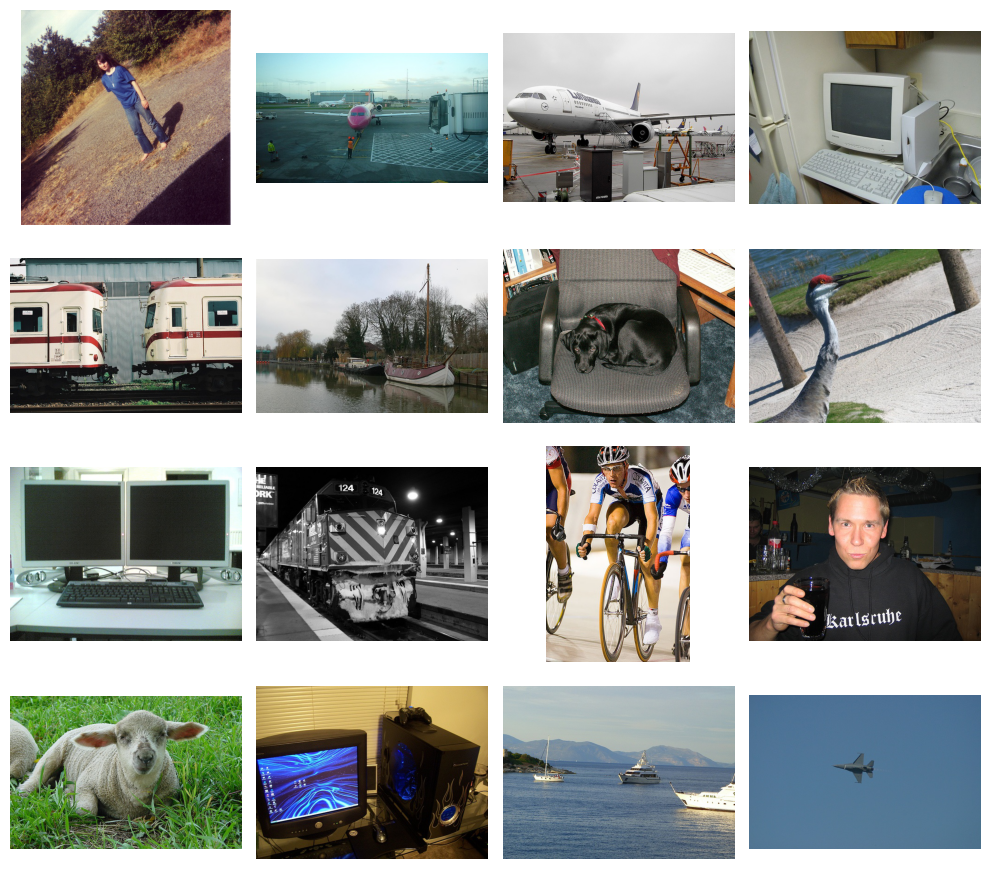

In [23]:
fig, ax = plt.subplots(4, 4, figsize=(10,9))

ax = ax.flatten()
for i in range(16):
    ax[i].imshow(Image.open(images_path[i]))
    ax[i].axis("off")

plt.tight_layout()
plt.show()

In [40]:
img = Image.open(images_path[111])
print(f"PIL img size (width, height): {img.size}")
print(f"NumPy img shape (height, width, channels): {np.array(img).shape, np.array(img).dtype}")

PIL img size (width, height): (375, 500)
NumPy img shape (height, width, channels): ((500, 375, 3), dtype('uint8'))


In [55]:
info = []

for path in images_path:
    with Image.open(path) as img:
        gray_img = img.convert('L')
        width, height = img.size

        info.append({
            'filename': path.name,
            'width': width,
            'height': height,
            'aspect_ratio': round(width / height, 3),
            'brightness': round(np.array(gray_img).mean(), 3),
            'channels': len(img.getbands()),
            'mode': img.mode,
            'file_size_kb': round(path.stat().st_size / 1024, 2)
        })

info_df = pd.DataFrame(info)

In [56]:
info_df.head()

,filename,width,height,aspect_ratio,brightness,channels,mode,file_size_kb
0,2007_000027.jpg,486,500,0.972,105.647,3,RGB,142.08
1,2007_000032.jpg,500,281,1.779,125.636,3,RGB,53.47
2,2007_000033.jpg,500,366,1.366,161.763,3,RGB,69.54
3,2007_000039.jpg,500,375,1.333,131.606,3,RGB,63.15
4,2007_000042.jpg,500,335,1.493,121.003,3,RGB,80.91


In [87]:
print(f'Количесво возможных каналов в изображениях: {info_df['channels'].nunique()}')
print(f'Количесво возможных mode в изображениях: {info_df['mode'].nunique()}')

Количесво возможных каналов в изображениях: 1
Количесво возможных mode в изображениях: 1


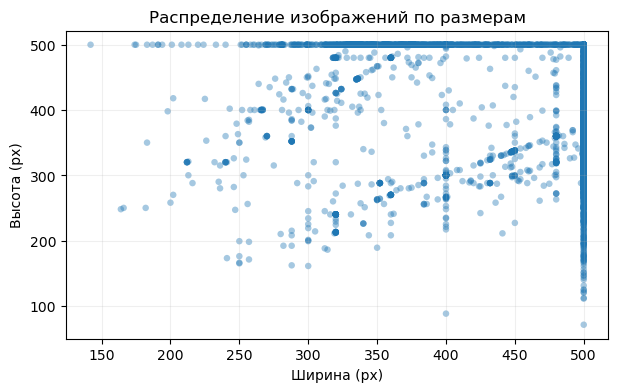

In [71]:
figure, ax = plt.subplots(figsize=(7, 4))

sns.scatterplot(data=info_df,
                x='width',
                y='height',
                ax=ax,
                s=22,
                edgecolor='none',
                alpha=0.4)
plt.grid(alpha=0.2)
plt.title('Распределение изображений по размерам')
plt.xlabel('Ширина (px)')
plt.ylabel('Высота (px)')
plt.show()

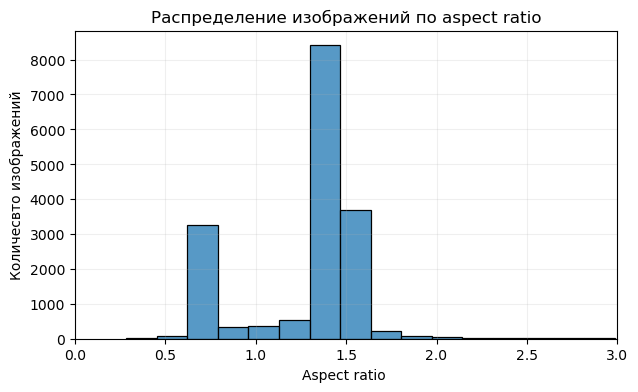

In [77]:
figure, ax = plt.subplots(figsize=(7, 4))

sns.histplot(data=info_df,
             x='aspect_ratio',
             bins=40)

plt.grid(alpha=0.2)
plt.xlim((0, 3))
plt.title('Распределение изображений по aspect ratio')
plt.xlabel('Aspect ratio ')
plt.ylabel('Количесвто изображений')
plt.show()

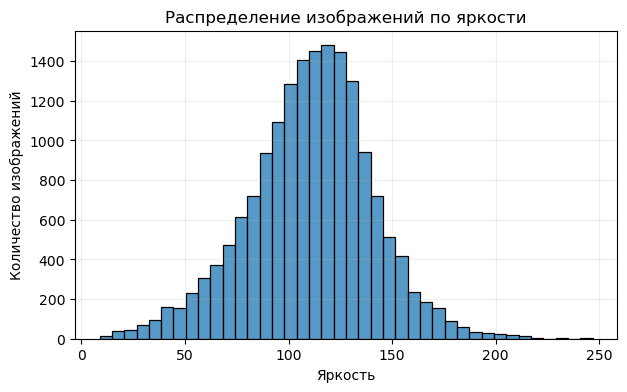

In [89]:
figure, ax = plt.subplots(figsize=(7, 4))

sns.histplot(data=info_df,
             x='brightness',
             bins=40)

plt.grid(alpha=0.2)
plt.title('Распределение изображений по яркости')
plt.xlabel('Яркость')
plt.ylabel('Количество изображений')
plt.show()

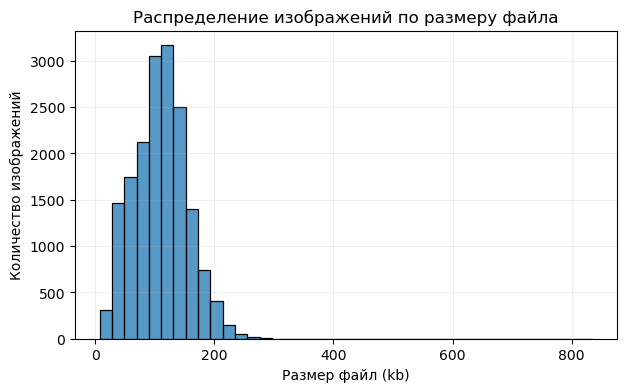

In [90]:
figure, ax = plt.subplots(figsize=(7, 4))

sns.histplot(data=info_df,
             x='file_size_kb',
             bins=40)

plt.grid(alpha=0.2)
plt.title('Распределение изображений по размеру файла')
plt.xlabel('Размер файл (kb)')
plt.ylabel('Количество изображений')
plt.show()

По результам анализа таблицы df_info, которая была собрана что бы получить количественную информацию по данным изображениям сделаны следующие выводы:
- Большинство изображений имеют ширину или высоту около 500 пикселей
- Преобладают горизонтальные фотографии с aspect ratio 1.3–1.5, однако вертикальные изображения также встречаются достаточно часто поэтому при подготовке данных это нужно будеть учесть 
- Распределение средней яркости сосредоточено преимущественно в диапазоне 75–155
- Большинство файлов занимают около 30–170 КиБ
- Количество каналов и цветовой режим одинаковы для всех изображений



In [91]:
info_df.sort_values(by='brightness', ascending=False)

,filename,width,height,aspect_ratio,brightness,channels,mode,file_size_kb
1470,2008_001448.jpg,500,274,1.825,246.889,3,RGB,21.94
12486,2011_002269.jpg,500,375,1.333,243.250,3,RGB,32.27
8678,2010_001731.jpg,500,500,1.000,236.402,3,RGB,20.91
11796,2011_000922.jpg,437,287,1.523,232.959,3,RGB,30.81
7865,2010_000091.jpg,500,333,1.502,231.227,3,RGB,11.86
...,...,...,...,...,...,...,...,...
10695,2010_005754.jpg,374,500,0.748,10.494,3,RGB,59.03
14666,2011_006638.jpg,423,500,0.846,10.208,3,RGB,77.11
1893,2008_002296.jpg,375,500,0.750,9.910,3,RGB,111.94
14229,2011_005762.jpg,500,333,1.502,9.101,3,RGB,77.77


In [95]:
info_df['px_count'] = info_df['px_count'] = info_df['width'] * info_df['height']
darkness = info_df.sort_values(by='brightness')[:3].filename
lightness = info_df.sort_values(by='brightness', ascending=False)[:3].filename

smallest = info_df.sort_values(by='px_count')[:3].filename

vertical = info_df.sort_values(by='aspect_ratio')[:3].filename

horizontal = info_df.sort_values(by='aspect_ratio', ascending=False)[:3].filename

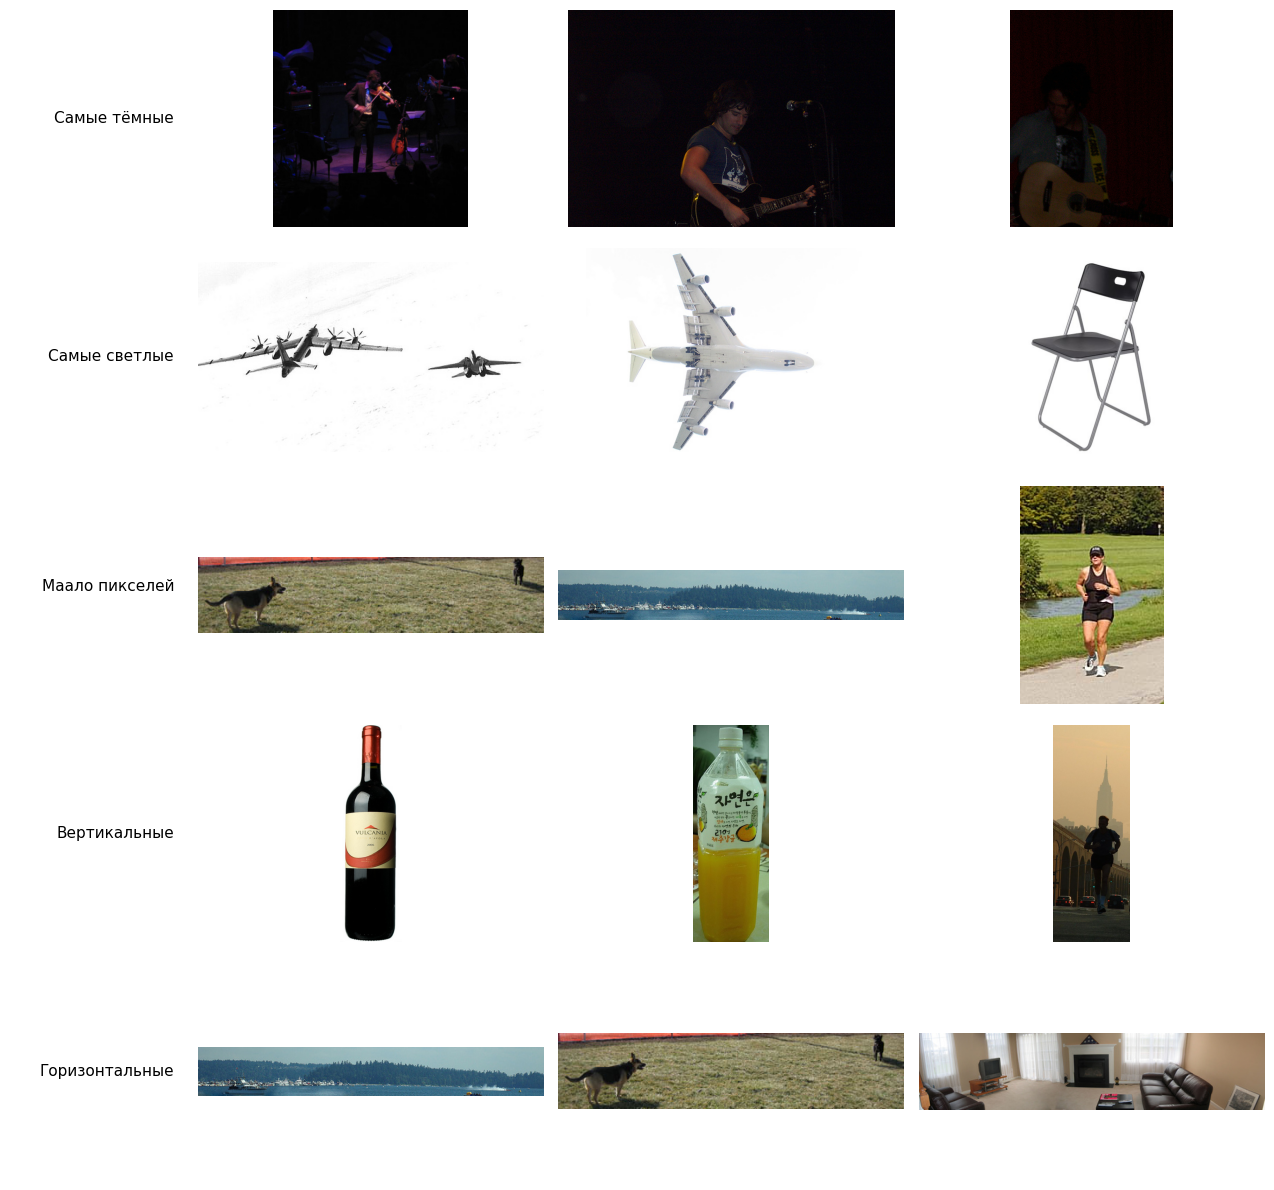

In [96]:
groups = {
    'Самые тёмные': darkness,
    'Самые светлые': lightness,
    'Маало пикселей\n': smallest,
    'Вертикальные': vertical,
    'Горизонтальные': horizontal
}
path_by_name = {path.name: path for path in images_path}

fig, axes = plt.subplots(5, 4,figsize=(13, 12),gridspec_kw={'width_ratios': [1.5, 3, 3, 3]})
for row, (label, filenames) in enumerate(groups.items()):
    axes[row, 0].text(0.95, 0.5, label,
                      ha='right', va='center',
                      fontsize=11)
    axes[row, 0].axis('off')
    for col, filename in enumerate(filenames, start=1):
        with Image.open(path_by_name[filename]) as img:
            axes[row, col].imshow(img)

        axes[row, col].axis('off')

plt.tight_layout(h_pad=1.5)
plt.show()

In [97]:
from sklearn.model_selection import train_test_split

train_files, temp_files = train_test_split(info_df['filename'],
                                           test_size=0.3,random_state=42)

val_files, test_files = train_test_split(temp_files,
                                         test_size=0.5,random_state=42)

In [98]:
from pathlib import Path

split_dir = Path("../data/splits")
split_dir.mkdir(parents=True, exist_ok=True)

train_files.to_csv(split_dir / "train.txt", index=False, header=False)
val_files.to_csv(split_dir / "val.txt", index=False, header=False)
test_files.to_csv(split_dir / "test.txt", index=False, header=False)

Списки файлов сохранены для дальнейшего использования во всех экспериментах